# Teacher from scratch: SE-WRN-28-10 + SLA (attention, training-only)

A self-contained Colab notebook (no git, no patch). It trains one big teacher on **our** 45k training split from random
weights, using the recipe of your team's best teacher (t04: WRN-28-10 + SLA, val 0.9850 on their split):
250 epochs, batch 128 (x 4 rotations), SGD Nesterov 0.9, LR 0.1, weight decay 5e-4, 2 warm-up epochs + cosine,
TrivialAugment, crop + flip, Cutout 16, CutMix on 50% of batches, no label smoothing, SLA + self-distillation.
The one change: an SE block (squeeze-excitation = channel attention, Hu et al. 2018) on every residual branch.
Staff confirmed on Slack (Nov 2, 5:41 pm) that attention is fine in teachers trained from scratch.

It is never submitted (36.8M params). `best.pt` is saved in our teacher format for the next distillation run.

Runtime → A100, then Run all. If Colab disconnects, Run all again: training resumes from `last.pt`.

## 1. Config

In [1]:
CFG = dict(
    RUN_NAME="teacher_sewrn28_10_sla250_v1",
    DRIVE_PROJECT_DIR="cifar10_resnet_challenge",
    SPLIT_FILE="split_seed42_val0.05_test0.05_n50000.npz",
    SEED=51,

    # model: WRN-28-10 (pre-activation) + SE on every block + SLA head
    DEPTH=28, WIDEN=10, SE_REDUCTION=16,

    # training (team t04 recipe)
    EPOCHS=250, BATCH_SIZE=128, LR=0.1, MOMENTUM=0.9, WEIGHT_DECAY=5e-4, WARMUP_EPOCHS=2,

    # augmentation
    TA_GROUP=16, CUTOUT=16, MIX_PROB=0.5, CUTMIX_ALPHA=1.0,
)
CFG

{'RUN_NAME': 'teacher_sewrn28_10_sla250_v1',
 'DRIVE_PROJECT_DIR': 'cifar10_resnet_challenge',
 'SPLIT_FILE': 'split_seed42_val0.05_test0.05_n50000.npz',
 'SEED': 51,
 'DEPTH': 28,
 'WIDEN': 10,
 'SE_REDUCTION': 16,
 'EPOCHS': 250,
 'BATCH_SIZE': 128,
 'LR': 0.1,
 'MOMENTUM': 0.9,
 'WEIGHT_DECAY': 0.0005,
 'WARMUP_EPOCHS': 2,
 'TA_GROUP': 16,
 'CUTOUT': 16,
 'MIX_PROB': 0.5,
 'CUTMIX_ALPHA': 1.0}

## 2. Setup

In [2]:
import os, json, time, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision.transforms import v2 as T
from google.colab import drive

drive.mount("/content/drive")
ROOT = os.path.join("/content/drive/MyDrive", CFG["DRIVE_PROJECT_DIR"])
CACHE = os.path.join(ROOT, "data", "cache")
RUN_DIR = os.path.join(ROOT, "runs", CFG["RUN_NAME"]); os.makedirs(RUN_DIR, exist_ok=True)
LAST, BEST = os.path.join(RUN_DIR, "last.pt"), os.path.join(RUN_DIR, "best.pt")

device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
torch.manual_seed(CFG["SEED"]); np.random.seed(CFG["SEED"])
print("GPU:", torch.cuda.get_device_name(0), "| run dir:", RUN_DIR)

def save(obj, path):
    torch.save(obj, path + ".tmp"); os.replace(path + ".tmp", path)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

Mounted at /content/drive
GPU: NVIDIA A100-SXM4-40GB | run dir: /content/drive/MyDrive/cifar10_resnet_challenge/runs/teacher_sewrn28_10_sla250_v1


## 3. Data (same 45k / 2.5k / 2.5k split as all our runs)

In [3]:
X = np.load(os.path.join(CACHE, "train_x.npy")); y = np.load(os.path.join(CACHE, "train_y.npy"))
split = np.load(os.path.join(ROOT, "data", "splits", CFG["SPLIT_FILE"]))
def gpu(a): return torch.from_numpy(a).permute(0, 3, 1, 2).contiguous().to(device)
Xtr, ytr = gpu(X[split["train"]]), torch.from_numpy(y[split["train"]]).to(device)
Xva, yva = gpu(X[split["val"]]), torch.from_numpy(y[split["val"]]).to(device)
Xte, yte = gpu(X[split["test"]]), torch.from_numpy(y[split["test"]]).to(device)
_f = Xtr.float() / 255                                   # same statistics as every other run
MEAN = _f.mean(dim=(0, 2, 3)).view(1, 3, 1, 1); STD = _f.std(dim=(0, 2, 3)).view(1, 3, 1, 1); del _f
def normalize(x): return ((x.float() / 255 - MEAN) / STD).contiguous(memory_format=torch.channels_last)
print("train", len(Xtr), "| val", len(Xva), "| internal test", len(Xte))

train 45000 | val 2500 | internal test 2500


## 4. Augmentation: TrivialAugment, crop + flip, Cutout 16, CutMix

In [4]:
trivial = T.TrivialAugmentWide()

def augment(x_u8):
    n, ar = len(x_u8), torch.arange(32, device=device)
    x_u8 = torch.cat([trivial(c) for c in x_u8.split(CFG["TA_GROUP"])])
    x = (x_u8.float() / 255 - MEAN) / STD
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    dy, dx = torch.randint(0, 9, (n,), device=device), torch.randint(0, 9, (n,), device=device)
    x = xp[torch.arange(n, device=device)[:, None, None, None], torch.arange(3, device=device)[None, :, None, None],
           (dy[:, None] + ar)[:, None, :, None], (dx[:, None] + ar)[:, None, None, :]]
    flip = torch.rand(n, device=device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    cy, cx, h = torch.randint(0, 32, (n,), device=device), torch.randint(0, 32, (n,), device=device), CFG["CUTOUT"] // 2
    hole = ((ar[None, :, None] - cy[:, None, None]).abs() < h) & ((ar[None, None, :] - cx[:, None, None]).abs() < h)
    return (x * (~hole)[:, None].float()).contiguous(memory_format=torch.channels_last)

def cutmix(x, y):
    """Paste a random box from a shuffled copy of the batch; labels mixed by the pasted area (Yun et al. 2019)."""
    lam = np.random.beta(CFG["CUTMIX_ALPHA"], CFG["CUTMIX_ALPHA"])
    idx = torch.randperm(len(x), device=device)
    r = math.sqrt(1 - lam); ch, cw = int(32 * r), int(32 * r)
    cy, cx = np.random.randint(32), np.random.randint(32)
    y1, y2, x1, x2 = max(cy - ch // 2, 0), min(cy + ch // 2, 32), max(cx - cw // 2, 0), min(cx + cw // 2, 32)
    x = x.clone(); x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    return x, y, y[idx], 1 - (y2 - y1) * (x2 - x1) / 1024

## 5. Model: SE-WRN-28-10 (pre-activation) + SLA head

In [5]:
class SE(nn.Module):
    """Squeeze-excitation (Hu et al. 2018): channel weights from global average pooling."""
    def __init__(self, c, r=16):
        super().__init__()
        self.fc1, self.fc2 = nn.Conv2d(c, c // r, 1), nn.Conv2d(c // r, c, 1)
    def forward(self, x):
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(F.adaptive_avg_pool2d(x, 1)))))

class WBlock(nn.Module):
    """Pre-activation wide residual block (Zagoruyko & Komodakis 2016), optional SE on the residual branch."""
    def __init__(self, cin, cout, stride, drop=0.0, se_r=0):
        super().__init__()
        self.bn1, self.conv1 = nn.BatchNorm2d(cin), nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn2, self.conv2 = nn.BatchNorm2d(cout), nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.dropout = nn.Dropout(drop)
        self.skip = None if (stride == 1 and cin == cout) else nn.Conv2d(cin, cout, 1, stride, bias=False)
        if se_r: self.se = SE(cout, se_r)
    def forward(self, x):
        o = F.relu(self.bn1(x))
        sc = x if self.skip is None else self.skip(o)
        o = self.conv2(self.dropout(F.relu(self.bn2(self.conv1(o)))))
        if hasattr(self, "se"): o = self.se(o)
        return o + sc

class WRN(nn.Module):
    def __init__(self, depth=28, k=10, dropout=0.0, num_classes=10, se_r=0):
        super().__init__()
        n = (depth - 4) // 6
        w = [16] + (list(k) if isinstance(k, (tuple, list)) else [16 * k, 32 * k, 64 * k])
        self.stem = nn.Conv2d(3, w[0], 3, 1, 1, bias=False)
        layers, cin = [], w[0]
        for i in range(3):
            for j in range(n):
                layers.append(WBlock(cin, w[i + 1], 2 if (j == 0 and i > 0) else 1, dropout, se_r)); cin = w[i + 1]
        self.layers = nn.Sequential(*layers); self.bn = nn.BatchNorm2d(cin)
        self.drop = nn.Dropout(0.0); self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d) and m.bias is None:          # main convs; SE convs keep the default init
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def features(self, x):
        return torch.flatten(F.adaptive_avg_pool2d(F.relu(self.bn(self.layers(self.stem(x)))), 1), 1)
    def forward(self, x):
        return self.fc(self.drop(self.features(x)))
    def both(self, x):
        f = self.drop(self.features(x)); return self.fc(f), self.fc_joint(f)

model = WRN(CFG["DEPTH"], CFG["WIDEN"], se_r=CFG["SE_REDUCTION"])
model.fc_joint = nn.Linear(model.fc.in_features, 40)          # SLA head: 10 classes x 4 rotations
model = model.to(device).to(memory_format=torch.channels_last)
print(f"SE-WRN-{CFG['DEPTH']}-{CFG['WIDEN']} + SLA: {sum(p.numel() for p in model.parameters()):,} params "
      f"| SE blocks: {sum(isinstance(m, SE) for m in model.modules())} (teacher only, never submitted)")

SE-WRN-28-10 + SLA: 36,778,394 params | SE blocks: 12 (teacher only, never submitted)


## 6. Optimizer, schedule, prediction

In [6]:
decay = [p for p in model.parameters() if p.ndim > 1]; no_decay = [p for p in model.parameters() if p.ndim <= 1]
opt = torch.optim.SGD([{"params": decay, "weight_decay": CFG["WEIGHT_DECAY"]}, {"params": no_decay, "weight_decay": 0.0}],
                      lr=CFG["LR"], momentum=CFG["MOMENTUM"], nesterov=True)
steps = math.ceil(len(Xtr) / CFG["BATCH_SIZE"]); warm = CFG["WARMUP_EPOCHS"] * steps
sched = torch.optim.lr_scheduler.SequentialLR(opt, [
    torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.01, total_iters=warm),
    torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["EPOCHS"] * steps - warm)], milestones=[warm])

@torch.no_grad()
def predict(m, X, mode="sd", tta=True):
    """sd: 10-class head | ag: SLA head averaged over 4 rotations | sdag: mean of both; tta adds the flipped image."""
    m.eval(); out = []
    def probs(xb):
        if mode == "sd": return m(xb).float().softmax(1)
        ag = sum(m.both(torch.rot90(xb, k, (2, 3)))[1].float().view(-1, 10, 4)[:, :, k] for k in range(4)) / 4
        return ag.softmax(1) if mode == "ag" else 0.5 * (ag.softmax(1) + m(xb).float().softmax(1))
    for i in range(0, len(X), 500):
        xb = normalize(X[i:i + 500])
        with torch.autocast("cuda", dtype=torch.bfloat16):
            p = probs(xb)
            if tta: p = (p + probs(xb.flip(3))) / 2
        out.append(p)
    return torch.cat(out)
def acc(p, y): return (p.argmax(1) == y).float().mean().item()

## 7. Train (resumes from last.pt)

In [7]:
start, best_acc, history = 0, 0.0, []
if os.path.exists(LAST):
    ck = torch.load(LAST, map_location=device, weights_only=False)
    assert ck["cfg"] == CFG, "Config changed since this run started: use a new RUN_NAME"
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    start, best_acc, history = ck["epoch"], ck["best_acc"], ck["history"]
    print(f"resumed at epoch {start}, best val {best_acc:.4f}")

rot = torch.arange(4, device=device)
TEACHER_CFG = dict(ARCH="sewrn", DEPTH=CFG["DEPTH"], WIDEN=CFG["WIDEN"], SE_REDUCTION=CFG["SE_REDUCTION"], DROPOUT=0.0,
                   SLA=True, SLA_ROTATIONS=4, SPLIT_SEED=42, VAL_FRAC=0.05, TEST_FRAC=0.05, RUN_NAME=CFG["RUN_NAME"])

for epoch in range(start, CFG["EPOCHS"]):
    t0 = time.time(); model.train()
    tot, correct = torch.zeros((), device=device), torch.zeros((), device=device)
    perm = torch.randperm(len(Xtr), device=device)
    for i in range(0, len(Xtr), CFG["BATCH_SIZE"]):
        idx = perm[i:i + CFG["BATCH_SIZE"]]; B = len(idx)
        x, ya, yb, lam = augment(Xtr[idx]), ytr[idx], ytr[idx], 1.0
        if np.random.rand() < CFG["MIX_PROB"]:
            x, ya, yb, lam = cutmix(x, ya)
        x4 = torch.cat([torch.rot90(x, k, (2, 3)) for k in range(4)]).contiguous(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            sd_lo, j_lo = model.both(x4)
        sd_lo, j_lo = sd_lo.float(), j_lo.float()
        joint = lambda t: F.cross_entropy(j_lo, t.repeat(4) * 4 + rot.repeat_interleave(B))
        l_sla = lam * joint(ya) + (1 - lam) * joint(yb)                                    # SLA joint labels
        agg = torch.stack([j_lo.view(4, B, 10, 4)[k, :, :, k] for k in range(4)]).mean(0)
        sd0 = sd_lo[:B]
        l_sd = F.kl_div(F.log_softmax(sd0, 1), F.softmax(agg.detach(), 1), reduction="batchmean")   # self-distillation
        loss = l_sla + l_sd
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        tot += loss.detach() * B; correct += (sd0.argmax(1) == ya).sum()

    val_acc = acc(predict(model, Xva, tta=False), yva)
    history.append({"epoch": epoch + 1, "loss": tot.item() / len(Xtr), "train_acc": correct.item() / len(Xtr),
                    "val_acc": val_acc, "lr": sched.get_last_lr()[0], "sec": time.time() - t0})
    if val_acc > best_acc:
        best_acc = val_acc
        save({"model": model.state_dict(), "cfg": TEACHER_CFG, "epoch": epoch + 1, "val_acc": val_acc,
              "norm": {"mean": MEAN.cpu(), "std": STD.cpu()}, "is_ema": False}, BEST)
    save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "epoch": epoch + 1,
          "best_acc": best_acc, "history": history, "cfg": CFG}, LAST)
    h = history[-1]
    print(f"ep {epoch+1:3d}/{CFG['EPOCHS']} | loss {h['loss']:.4f} | train acc {h['train_acc']:.4f} | val {val_acc:.4f}"
          f"{' *' if best_acc == val_acc else '  '} | lr {h['lr']:.4f} | {h['sec']:.0f}s | eta {(CFG['EPOCHS']-epoch-1)*h['sec']/3600:.1f} h")
pd.DataFrame(history).to_csv(os.path.join(RUN_DIR, "history.csv"), index=False)
print("done, best val", best_acc)

resumed at epoch 134, best val 0.9572
ep 135/250 | loss 1.2008 | train acc 0.7602 | val 0.9628 * | lr 0.0443 | 72s | eta 2.3 h
ep 136/250 | loss 1.2694 | train acc 0.7220 | val 0.9564   | lr 0.0437 | 49s | eta 1.5 h
ep 137/250 | loss 1.1917 | train acc 0.7455 | val 0.9428   | lr 0.0431 | 49s | eta 1.5 h
ep 138/250 | loss 1.1617 | train acc 0.7642 | val 0.9564   | lr 0.0424 | 49s | eta 1.5 h
ep 139/250 | loss 1.2031 | train acc 0.7555 | val 0.9436   | lr 0.0418 | 49s | eta 1.5 h
ep 140/250 | loss 1.2113 | train acc 0.7295 | val 0.9532   | lr 0.0412 | 49s | eta 1.5 h
ep 141/250 | loss 1.1625 | train acc 0.7528 | val 0.9528   | lr 0.0406 | 49s | eta 1.5 h
ep 142/250 | loss 1.1619 | train acc 0.7623 | val 0.9440   | lr 0.0399 | 49s | eta 1.5 h
ep 143/250 | loss 1.1725 | train acc 0.7570 | val 0.9520   | lr 0.0393 | 49s | eta 1.5 h
ep 144/250 | loss 1.1716 | train acc 0.7568 | val 0.9596   | lr 0.0387 | 49s | eta 1.4 h
ep 145/250 | loss 1.1373 | train acc 0.7652 | val 0.9512   | lr 0.0381 |

## 8. Evaluate best.pt: validation, internal test, per class, heatmap, curves

best.pt epoch 233 | val {'sd': 0.988, 'ag': 0.986, 'sdag': 0.9884} -> sdag
INTERNAL TEST 0.9848   (our best 5M student: 0.9804; best 5M teacher so far: 0.9808)
        airplane  automobile  bird    cat   deer    dog   frog  horse   ship  truck
recall     0.988       0.984  0.98  0.976  0.992  0.976  0.988  0.972  0.992    1.0
errors     3.000       4.000  5.00  6.000  2.000  6.000  3.000  7.000  2.000    0.0
top confusions (true -> predicted): 5 cat->dog, 4 dog->cat, 4 automobile->truck, 3 horse->dog, 3 horse->deer, 3 bird->cat


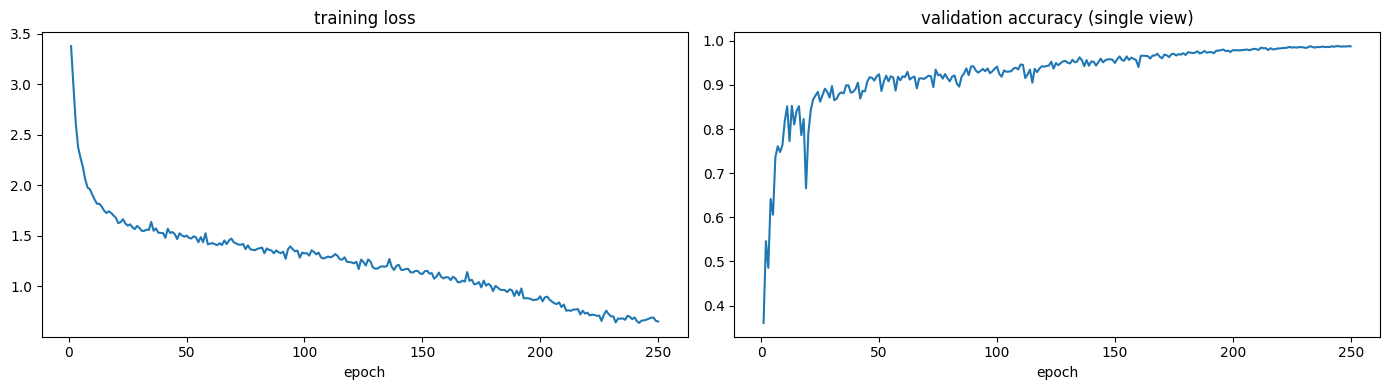

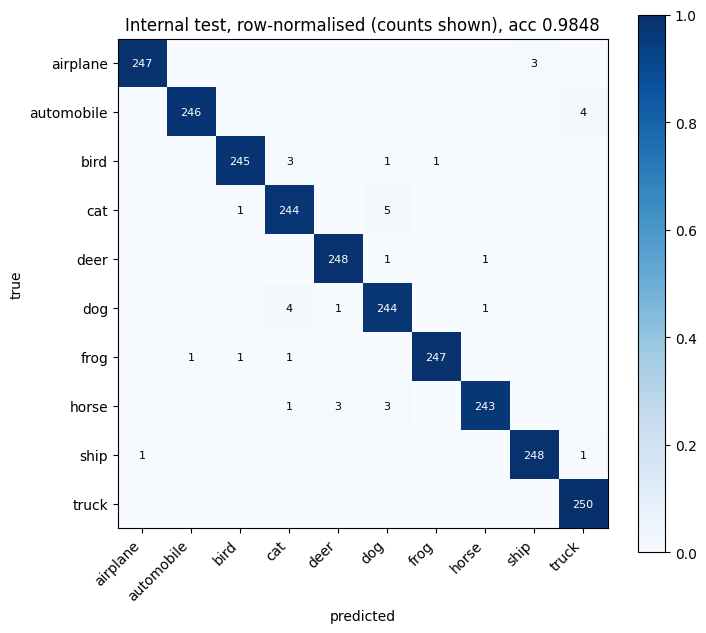

In [8]:
best = torch.load(BEST, map_location=device, weights_only=False)
model.load_state_dict(best["model"]); model.eval()
val_accs = {m: acc(predict(model, Xva, m), yva) for m in ("sd", "ag", "sdag")}
MODE = max(val_accs, key=val_accs.get)
p_te = predict(model, Xte, MODE); test_acc = acc(p_te, yte)
print(f"best.pt epoch {best['epoch']} | val {({k: round(v, 4) for k, v in val_accs.items()})} -> {MODE}")
print(f"INTERNAL TEST {test_acc:.4f}   (our best 5M student: 0.9804; best 5M teacher so far: 0.9808)")
cm = torch.bincount(yte * 10 + p_te.argmax(1), minlength=100).view(10, 10).cpu()
print(pd.DataFrame({"recall": (cm.diag() / cm.sum(1)).numpy().round(3), "errors": (cm.sum(1) - cm.diag()).numpy()}, index=CLASSES).T.to_string())
off = cm.clone(); off.fill_diagonal_(0)
top = sorted(((int(off[i, j]), CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if off[i, j] > 0), reverse=True)[:6]
print("top confusions (true -> predicted):", ", ".join(f"{n} {a}->{c}" for n, a, c in top))

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(h["epoch"], h["loss"]); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h["epoch"], h["val_acc"]); ax[1].set_title("validation accuracy (single view)"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "curves.png"), dpi=110); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
cmn = cm.float() / cm.sum(1, keepdim=True).float()
im = ax.imshow(cmn.numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0: ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Internal test, row-normalised (counts shown), acc {test_acc:.4f}")
plt.colorbar(im); plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "confusion_internal_test.png"), dpi=120); plt.show()